# 24 - Rainfall Trends in India, 1901-2015: is there a trend, and what counts as a drought?
**Topic:** Data Visualization  |  **Reference:** "Rainfall Trends in India Analysis with Python" (amanxai.com, Nov 2024)

**Question.** Has India's rainfall changed over the 20th century, how much does it vary, and how often do dry and wet extremes occur?

**Reference method:** plot annual rainfall and a 10-year moving average, read "no apparent long-term trend" off the picture, flag years beyond +/-1.5 standard deviations as drought / extreme-rain years, and apply an Isolation Forest.
**What I add:** (1) audit the file's arithmetic; (2) **test** the trend (ordinary regression with robust errors, and the non-parametric **Mann-Kendall test with Sen's slope**) and show how much the answer **depends on the period** chosen; (3) test for **persistence** and **multi-decade swings** (the reason a picture can look like a trend); (4) show that the Isolation Forest on one column is only a threshold in disguise; (5) count extremes by period, with the uncertainty that few events bring.

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.stattools import acf
from sklearn.ensemble import IsolationForest
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("model", exist_ok=True)
r = pd.read_csv("../_data/rainfall.csv").set_index("YEAR"); M = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"]
print(r.shape, r.index.min(), "to", r.index.max(), "| regions:", r.REGION.unique().tolist(), "| missing:", int(r.isna().sum().sum())); r.head(3)

(115, 18) 1901 to 2015 | regions: ['INDIA'] | missing: 0


,REGION,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
YEAR,,,,,,,,,,,,,,,,,,
1901,INDIA,34.7,37.7,18.0,39.3,50.8,113.4,242.2,272.9,124.4,52.7,38.0,8.3,1032.3,72.4,108.1,752.8,99.0
1902,INDIA,7.4,4.3,19.0,43.5,48.3,108.8,284.0,199.7,201.5,61.5,27.9,24.4,1030.2,11.7,110.8,794.0,113.8
1903,INDIA,17.0,8.3,31.3,17.1,59.5,118.3,297.0,270.4,199.1,117.9,36.9,17.7,1190.5,25.3,107.9,884.8,172.5


## 2. Audit: does the file add up?

In [2]:
chk = pd.DataFrame({"annual - sum of months": r.ANNUAL - r[M].sum(1), "Jun-Sep - sum(Jun..Sep)": r["Jun-Sep"] - r[["JUN", "JUL", "AUG", "SEP"]].sum(1), "Jan-Feb - sum": r["Jan-Feb"] - r[["JAN", "FEB"]].sum(1), "Mar-May - sum": r["Mar-May"] - r[["MAR", "APR", "MAY"]].sum(1), "Oct-Dec - sum": r["Oct-Dec"] - r[["OCT", "NOV", "DEC"]].sum(1)})
print(chk.describe().loc[["mean", "min", "max"]].round(2).to_string())
print("\nannual rainfall: mean %.0f mm, sd %.0f mm (coefficient of variation %.1f%%), min %.0f in %d, max %.0f in %d" % (r.ANNUAL.mean(), r.ANNUAL.std(), r.ANNUAL.std() / r.ANNUAL.mean() * 100, r.ANNUAL.min(), r.ANNUAL.idxmin(), r.ANNUAL.max(), r.ANNUAL.idxmax()))
cl = pd.DataFrame({"mean_mm": r[M].mean(), "cv_%": r[M].std() / r[M].mean() * 100}); print("\nmonthly climatology:"); print(cl.round(0).T.to_string())
print("\nshare of annual rainfall by season (mean): %s" % (r[["Jan-Feb", "Mar-May", "Jun-Sep", "Oct-Dec"]].mean().div(r.ANNUAL.mean()).mul(100).round(0).to_dict()))

      annual - sum of months  Jun-Sep - sum(Jun..Sep)  Jan-Feb - sum  Mar-May - sum  Oct-Dec - sum
mean                    0.01                      0.0           -0.0            0.0           -0.0
min                    -0.20                     -0.1           -0.1           -0.1           -0.1
max                     0.30                      0.2            0.1            0.1            0.1

annual rainfall: mean 1182 mm, sd 111 mm (coefficient of variation 9.4%), min 921 in 2002, max 1480 in 1917

monthly climatology:
          JAN   FEB   MAR   APR   MAY    JUN    JUL    AUG    SEP   OCT   NOV   DEC
mean_mm  20.0  23.0  28.0  38.0  62.0  168.0  291.0  258.0  172.0  76.0  29.0  15.0
cv_%     51.0  49.0  43.0  27.0  25.0   21.0   14.0   14.0   21.0  37.0  55.0  59.0

share of annual rainfall by season (mean): {'Jan-Feb': 4.0, 'Mar-May': 11.0, 'Jun-Sep': 75.0, 'Oct-Dec': 10.0}


**Reading it.** The file adds up: annual totals equal the sum of the months and seasonal totals the sum of their months, to within rounding (differences of at most 0.3 mm). No missing years in 1901-2015 and a single region (all-India, area-weighted). Annual rainfall averages **1,182 mm with a standard deviation of 111 mm (9.4%)**: the driest year was 2002 (921 mm) and the wettest 1917 (1,480 mm). **The June-September monsoon delivers 75% of the year's rain** (July 291 mm and August 258 mm are the wettest months), January-February 4%, March-May 11%, October-December 10%. Relative to their size the monsoon months are the most reliable (coefficient of variation 14% for July and August) and the dry-season months the least (51-59% in December-February).

## 3. The picture: annual rainfall, moving averages, seasons

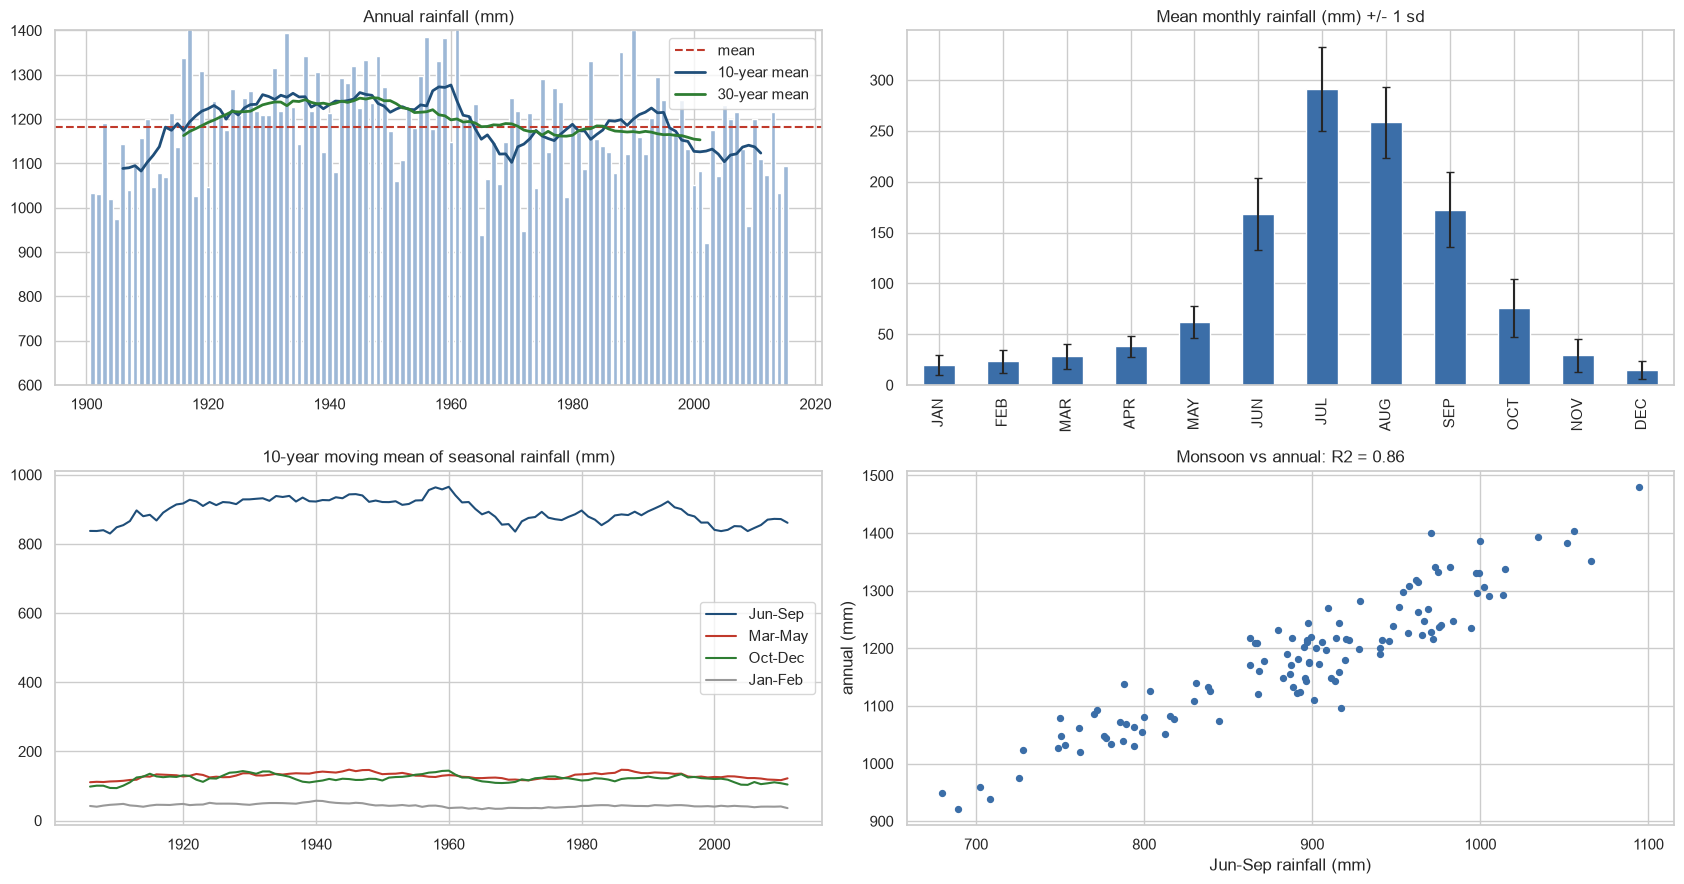

In [3]:
fig, ax = plt.subplots(2, 2, figsize=(17, 9))
ax[0, 0].bar(r.index, r.ANNUAL, color="#9db8d6"); ax[0, 0].axhline(r.ANNUAL.mean(), color="#c0392b", ls="--", label="mean"); ax[0, 0].plot(r.index, r.ANNUAL.rolling(10, center=True).mean(), color="#1f4e79", lw=2, label="10-year mean"); ax[0, 0].plot(r.index, r.ANNUAL.rolling(30, center=True).mean(), color="#2e7d32", lw=2, label="30-year mean"); ax[0, 0].set_title("Annual rainfall (mm)"); ax[0, 0].legend(); ax[0, 0].set_ylim(600, 1400)
r[M].mean().plot.bar(ax=ax[0, 1], color="#3b6ea8", yerr=r[M].std(), capsize=3); ax[0, 1].set_title("Mean monthly rainfall (mm) +/- 1 sd")
for s_, c in [("Jun-Sep", "#1f4e79"), ("Mar-May", "#c0392b"), ("Oct-Dec", "#2e7d32"), ("Jan-Feb", "#999")]: ax[1, 0].plot(r.index, r[s_].rolling(10, center=True).mean(), label=s_, color=c)
ax[1, 0].set_title("10-year moving mean of seasonal rainfall (mm)"); ax[1, 0].legend()
ax[1, 1].scatter(r["Jun-Sep"], r.ANNUAL, color="#3b6ea8", s=18); ax[1, 1].set_xlabel("Jun-Sep rainfall (mm)"); ax[1, 1].set_ylabel("annual (mm)"); ax[1, 1].set_title("Monsoon vs annual: R2 = %.2f" % (np.corrcoef(r["Jun-Sep"], r.ANNUAL)[0, 1] ** 2))
plt.tight_layout(); plt.show()

**Reading it.** The annual series swings by roughly +/-10% from year to year. The decade means run from about 1,080 mm in the 1900s (only nine years: 1901-09) up to **1,250-1,260 mm in the 1930s-40s**, then **1,100-1,215 mm from the 1960s on**; the 30-year moving mean peaks at about 1,248 mm around 1947 and bottoms at about 1,153 mm around 2001 (a swing of roughly 8%), and the 10-year mean ranges from about 1,083 mm (c. 1909) to 1,277 mm (c. 1960). So the series has **multi-decade swings but no steady direction over the whole century**. The monsoon alone explains most of the annual variation (R-squared 0.87 in the lower-right panel). The reference's reading "no apparent long-term trend" matches what the picture suggests; the next section tests it.

## 4. Is there a trend? Two tests and a sensitivity check
* **Regression** of annual rainfall on the year, with autocorrelation-robust (HAC) standard errors.
* **Mann-Kendall test** (non-parametric: does the series tend to rise or fall?) with **Sen's slope** (the median of all pairwise slopes), which does not depend on a few extreme years.
* Both for the annual total and for each season.

In [4]:
def mk(x):
    x = np.asarray(x, float); n = len(x); s = sum(np.sign(x[j] - x[i]) for i in range(n - 1) for j in range(i + 1, n)); var = n * (n - 1) * (2 * n + 5) / 18
    z = (s - np.sign(s)) / np.sqrt(var) if s != 0 else 0.0; sl = np.median([(x[j] - x[i]) / (j - i) for i in range(n - 1) for j in range(i + 1, n)]); return z, 2 * stats.norm.sf(abs(z)), sl
rows = []
for col in ["ANNUAL", "Jan-Feb", "Mar-May", "Jun-Sep", "Oct-Dec"]:
    y = r[col].to_numpy(); X = sm.add_constant(r.index.values - 1901.0); o = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 5}); z, p, sl = mk(y)
    rows.append([col, o.params[1] * 10, *(o.conf_int()[1] * 10), o.pvalues[1], sl * 10, p, o.params[1] * 10 / y.mean() * 100])
TR = pd.DataFrame(rows, columns=["series", "OLS mm/decade", "ci_low", "ci_high", "OLS p", "Sen slope mm/decade", "Mann-Kendall p", "OLS % of mean per decade"]).set_index("series"); print(TR.round(3).to_string())

         OLS mm/decade  ci_low  ci_high  OLS p  Sen slope mm/decade  Mann-Kendall p  OLS % of mean per decade
series                                                                                                       
ANNUAL          -2.967 -12.066    6.133  0.523               -2.722           0.390                    -0.251
Jan-Feb         -0.710  -1.354   -0.066  0.031               -0.716           0.081                    -1.644
Mar-May          0.313  -1.198    1.823  0.685                0.170           0.802                     0.243
Jun-Sep         -2.261  -8.508    3.987  0.478               -2.536           0.313                    -0.254
Oct-Dec         -0.310  -2.536    1.915  0.785               -0.250           0.841                    -0.259


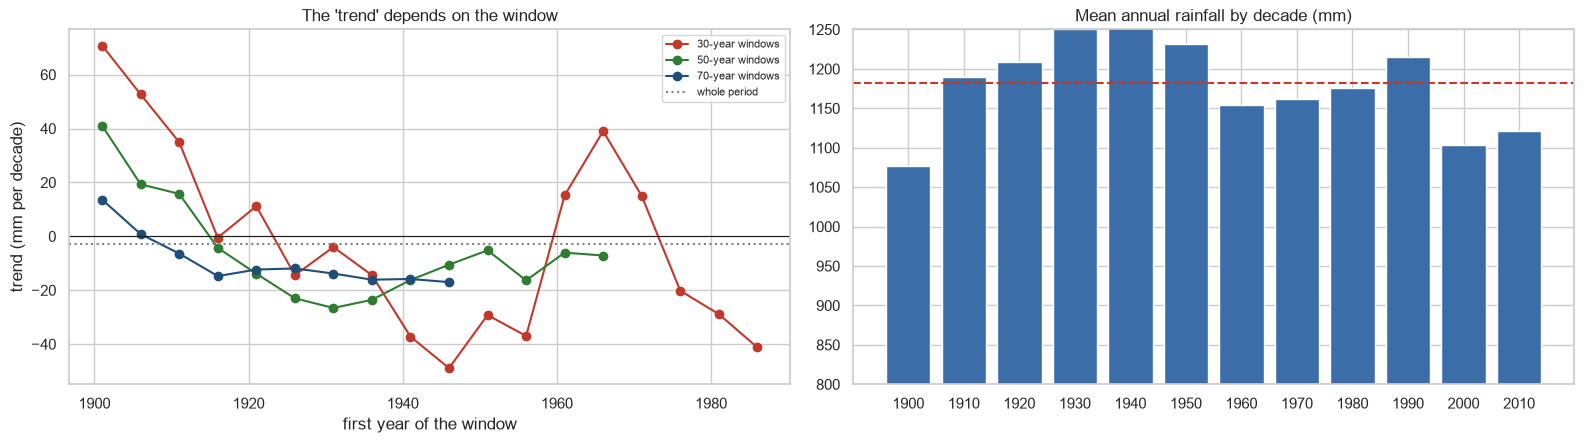

share of 30-year windows with a negative slope: 61%, positive: 39%; range of 30-year slopes: -49 to 71 mm/decade


In [5]:
yrs = r.index.values; ann = r.ANNUAL.to_numpy(); res = []
for L in (30, 50, 70):
    for s0 in range(0, len(r) - L + 1, 5): sl = np.polyfit(yrs[s0:s0 + L], ann[s0:s0 + L], 1)[0] * 10; res.append((L, yrs[s0], sl))
RS = pd.DataFrame(res, columns=["window_years", "start_year", "slope_mm_per_decade"])
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6))
for L, c in zip((30, 50, 70), ("#c0392b", "#2e7d32", "#1f4e79")): d = RS[RS.window_years == L]; ax[0].plot(d.start_year, d.slope_mm_per_decade, "o-", color=c, label=f"{L}-year windows")
ax[0].axhline(0, color="k", lw=.8); ax[0].axhline(TR.loc["ANNUAL", "OLS mm/decade"], color="gray", ls=":", label="whole period"); ax[0].set_xlabel("first year of the window"); ax[0].set_ylabel("trend (mm per decade)"); ax[0].set_title("The 'trend' depends on the window"); ax[0].legend(fontsize=8)
dec = r.ANNUAL.groupby((r.index // 10) * 10).mean(); ax[1].bar(dec.index.astype(str), dec.values, color="#3b6ea8"); ax[1].axhline(r.ANNUAL.mean(), color="#c0392b", ls="--"); ax[1].set_ylim(800, 1250); ax[1].set_title("Mean annual rainfall by decade (mm)")
plt.tight_layout(); plt.show()
print("share of 30-year windows with a negative slope: %.0f%%, positive: %.0f%%; range of 30-year slopes: %.0f to %.0f mm/decade" % ((RS[RS.window_years == 30].slope_mm_per_decade < 0).mean() * 100, (RS[RS.window_years == 30].slope_mm_per_decade > 0).mean() * 100, RS[RS.window_years == 30].slope_mm_per_decade.min(), RS[RS.window_years == 30].slope_mm_per_decade.max()))

**Reading it.**
* **No significant trend in annual rainfall:** the regression slope is **-3.0 mm per decade (95% interval -12.1 to +6.1; p = 0.52)** and Sen's slope -2.7 mm per decade (Mann-Kendall p = 0.39); about -0.25% of the mean per decade. The interval covers changes from a 12 mm/decade fall to a 6 mm/decade rise: a century of data can exclude large trends but not small ones.
* For the monsoon (June-September) the figures are alike (-2.3 mm per decade, p = 0.48; Mann-Kendall p = 0.31). March-May and October-December are also flat. **Only January-February shows a nominal decline (-0.7 mm per decade, OLS p = 0.03, Mann-Kendall p = 0.08)**: with five tests, one p-value below 0.05 is about what chance offers (0.25 expected), and it concerns 4% of the annual rainfall.
* **The answer depends on the window.** Slopes of 30-year windows run from **-49 to +71 mm per decade**, 61% negative and 39% positive. Anyone who picks a window can "show" a drying or a wetting India; the full 115 years say neither. The decade bar chart shows the same swings without direction.

## 5. Memory in the series: persistence and multi-decade swings
If wet years tend to follow wet years, or if rainfall has slow swings, short windows will show "trends" that disappear. I test the autocorrelation of the annual series, of the **monsoon**, and compare the mean rainfall of **three 38-year thirds** (a simple test of whether the mean shifted).

autocorrelation of annual rainfall at lags 1-5: [0.13, 0.31, 0.19, -0.01, 0.15] | 95% band about +/-0.18
mean of thirds (1901-38, 1939-76, 1977-2015): [1186, 1202, 1159] mm
ANOVA on the three thirds: F = 1.49, p = 0.230 | Kruskal-Wallis p = 0.169
largest departure of the cumulative sum of anomalies (a change-point indicator): year 1964, 1640 mm-years


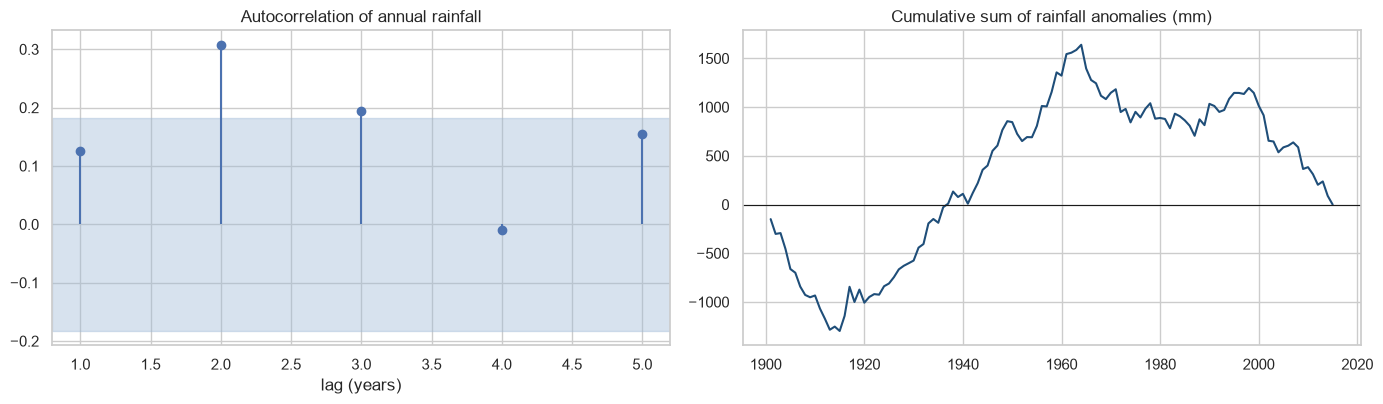

In [6]:
a1 = acf(ann - ann.mean(), nlags=5)[1:]; print("autocorrelation of annual rainfall at lags 1-5:", a1.round(2).tolist(), "| 95%% band about +/-%.2f" % (1.96 / np.sqrt(len(ann))))
thirds = [ann[:38], ann[38:76], ann[76:]]; print("mean of thirds (1901-38, 1939-76, 1977-2015): %s mm" % [round(float(x.mean())) for x in thirds]); F = stats.f_oneway(*thirds); print("ANOVA on the three thirds: F = %.2f, p = %.3f | Kruskal-Wallis p = %.3f" % (F.statistic, F.pvalue, stats.kruskal(*thirds).pvalue))
cs = np.cumsum(ann - ann.mean()); print("largest departure of the cumulative sum of anomalies (a change-point indicator): year %d, %.0f mm-years" % (yrs[np.argmax(np.abs(cs))], np.abs(cs).max()))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2)); ax[0].stem(range(1, 6), a1, basefmt=" "); ax[0].axhspan(-1.96 / np.sqrt(len(ann)), 1.96 / np.sqrt(len(ann)), color="#9db8d6", alpha=.4); ax[0].set_title("Autocorrelation of annual rainfall"); ax[0].set_xlabel("lag (years)")
ax[1].plot(yrs, cs, color="#1f4e79"); ax[1].axhline(0, color="k", lw=.8); ax[1].set_title("Cumulative sum of rainfall anomalies (mm)"); plt.tight_layout(); plt.show()

**Reading it.**
* **Mild persistence:** autocorrelation at lag 2 is 0.31 (outside the +/-0.18 band; lag 1 is 0.13 and lags 3-5 are 0.19, -0.01 and 0.15), so a wet year is slightly more often followed, two years later, by another wet one. This is enough to produce short stretches that look like trends.
* **No significant shift in the mean:** the three 38-year thirds average 1,186, 1,202 and 1,159 mm (ANOVA p = 0.23, Kruskal-Wallis p = 0.17). The cumulative sum of anomalies peaks in 1964: rainfall was on average above the long-term mean before the mid-1960s and slightly below it after, but the difference (about 40 mm between the middle third and the latest third) is within what chance produces for a series this variable.

## 6. Droughts and floods: definitions matter
The reference flags annual rainfall beyond 1.5 standard deviations of the mean. I use that rule, a 1.0-sd rule and a **percentile** rule (driest / wettest 10% of years), count events per 38-year third, and add the Isolation Forest on the same single column to see what it does.

beyond 1.5 sd -> dry: [1905, 1965, 1972, 2002, 2009] | wet: [1917, 1933, 1956, 1959, 1961, 1988, 1990]
beyond 1.0 sd -> dry 21 years, wet 20 years | percentile rule -> 12 + 12 years


Isolation Forest (10% contamination) on annual rainfall flags 12 years; identical to the driest/wettest-10% rule: False | overlap 12 of 12
                    1901-1938  1939-1976  1977-2015
dry years (<-1 sd)          9          6          6
wet years (>+1 sd)          7          9          4
dry (<-1.5 sd)              1          2          2
wet (>+1.5 sd)              2          3          2

expected under a normal distribution: P(< -1 sd) = 15.9% -> 18.2 of 115 years; P(< -1.5 sd) = 6.7% -> 7.7 years; observed skewness of annual rainfall: 0.02


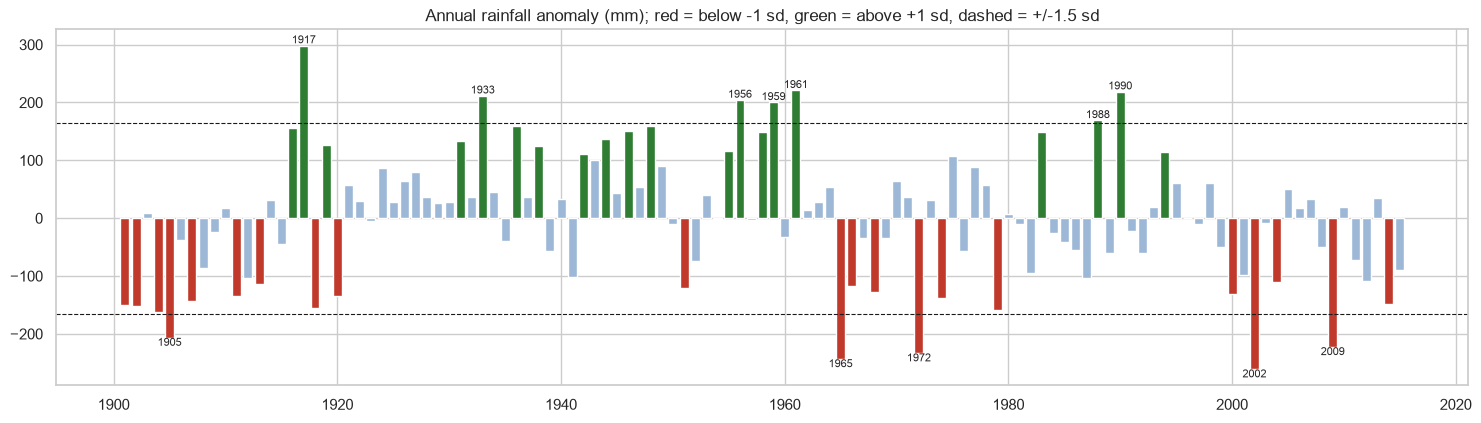

In [7]:
mu, sd = ann.mean(), ann.std(); dry15, wet15 = r.index[ann < mu - 1.5 * sd].tolist(), r.index[ann > mu + 1.5 * sd].tolist(); dry10, wet10 = r.index[ann < mu - 1.0 * sd].tolist(), r.index[ann > mu + 1.0 * sd].tolist()
q10, q90 = np.percentile(ann, [10, 90]); dryP, wetP = r.index[ann <= q10].tolist(), r.index[ann >= q90].tolist()
print("beyond 1.5 sd -> dry:", dry15, "| wet:", wet15); print("beyond 1.0 sd -> dry %d years, wet %d years | percentile rule -> %d + %d years" % (len(dry10), len(wet10), len(dryP), len(wetP)))
iso = IsolationForest(n_estimators=300, contamination=0.1, random_state=0).fit(r[["ANNUAL"]]); fl = r.index[iso.predict(r[["ANNUAL"]]) == -1].tolist(); print("Isolation Forest (10%% contamination) on annual rainfall flags %d years; identical to the driest/wettest-10%% rule: %s | overlap %d of %d" % (len(fl), set(fl) == set(dryP + wetP), len(set(fl) & set(dryP + wetP)), len(fl)))
blocks = [(1901, 1938), (1939, 1976), (1977, 2015)]; tab = pd.DataFrame({f"{a}-{b}": {"dry years (<-1 sd)": sum(a <= y <= b for y in dry10), "wet years (>+1 sd)": sum(a <= y <= b for y in wet10), "dry (<-1.5 sd)": sum(a <= y <= b for y in dry15), "wet (>+1.5 sd)": sum(a <= y <= b for y in wet15)} for a, b in blocks}); print(tab.to_string())
print("\nexpected under a normal distribution: P(< -1 sd) = %.1f%% -> %.1f of 115 years; P(< -1.5 sd) = %.1f%% -> %.1f years; observed skewness of annual rainfall: %.2f" % (stats.norm.cdf(-1) * 100, stats.norm.cdf(-1) * 115, stats.norm.cdf(-1.5) * 100, stats.norm.cdf(-1.5) * 115, stats.skew(ann)))
fig, ax = plt.subplots(figsize=(15, 4.4)); ax.bar(r.index, ann - mu, color=np.where(ann < mu - sd, "#c0392b", np.where(ann > mu + sd, "#2e7d32", "#9db8d6"))); ax.axhline(1.5 * sd, ls="--", color="k", lw=.8); ax.axhline(-1.5 * sd, ls="--", color="k", lw=.8)
for y_ in dry15 + wet15: ax.annotate(str(y_), (y_, ann[y_ - 1901] - mu), ha="center", va="bottom" if ann[y_ - 1901] > mu else "top", fontsize=8)
ax.set_title("Annual rainfall anomaly (mm); red = below -1 sd, green = above +1 sd, dashed = +/-1.5 sd"); plt.tight_layout(); plt.show()

**Reading it.**
* **The reference's results are reproduced** with its rule (beyond 1.5 standard deviations): dry years 1905, 1965, 1972, 2002 and 2009 (5) and wet years 1917, 1933, 1956, 1959, 1961, 1988, 1990 (7).
* **The count depends on the definition:** 5 + 7 years at 1.5 sd, 21 dry + 20 wet at 1 sd, and 12 + 12 for the driest and wettest 10%. Annual rainfall is almost perfectly symmetric (skewness 0.02) and the counts match what a normal distribution predicts (about 18 years beyond 1 sd on each side, 8 beyond 1.5 sd): there is **no excess of extreme years**. Extremes per 38-year block are 9, 6, 6 dry (beyond 1 sd) and 7, 9, 4 wet: small numbers with no clear shift.
* **The Isolation Forest adds nothing on one column:** with 10% contamination it flags 12 years, all of them in the 24 outermost years (driest/wettest 10%), i.e. it selects the values farthest from the middle: a threshold on the distance from the centre in disguise. It cannot say *why* a year is unusual.

## 7. Which months drive the dry years?
For the years beyond -1 sd, the mean anomaly of each month compared with all other years.

In [8]:
dryset = ann < mu - sd; contrib = (r.loc[dryset, M].mean() - r.loc[~dryset, M].mean()).round(1); share = (contrib / contrib.sum() * 100).round(0)
print("mean anomaly in dry years vs other years (mm), by month:", contrib.to_dict()); print("share of the annual deficit by month (%):", share.to_dict())
tt = {m: stats.ttest_ind(r.loc[dryset, m], r.loc[~dryset, m], equal_var=False).pvalue for m in M}; print("Welch t-test p by month (before correction; 12 tests):", {k: round(v, 3) for k, v in tt.items()})

mean anomaly in dry years vs other years (mm), by month: {'JAN': -1.3, 'FEB': -2.6, 'MAR': 1.2, 'APR': -2.3, 'MAY': -2.8, 'JUN': -24.7, 'JUL': -54.2, 'AUG': -42.7, 'SEP': -41.1, 'OCT': -21.3, 'NOV': -1.8, 'DEC': -2.4}
share of the annual deficit by month (%): {'JAN': 1.0, 'FEB': 1.0, 'MAR': -1.0, 'APR': 1.0, 'MAY': 1.0, 'JUN': 13.0, 'JUL': 28.0, 'AUG': 22.0, 'SEP': 21.0, 'OCT': 11.0, 'NOV': 1.0, 'DEC': 1.0}
Welch t-test p by month (before correction; 12 tests): {'JAN': np.float64(0.571), 'FEB': np.float64(0.368), 'MAR': np.float64(0.681), 'APR': np.float64(0.381), 'MAY': np.float64(0.439), 'JUN': np.float64(0.01), 'JUL': np.float64(0.0), 'AUG': np.float64(0.0), 'SEP': np.float64(0.0), 'OCT': np.float64(0.0), 'NOV': np.float64(0.658), 'DEC': np.float64(0.152)}


**Reading it.** In dry years (below -1 sd) the deficit is concentrated in the monsoon: July (-54 mm, 28% of the annual deficit), August (-43 mm, 22%), September (-41 mm, 21%) and June (-25 mm, 13%) add up to 84%, and October another 11%. Welch tests for these months are clearly significant (p = 0.01 for June, below 0.001 for July-October) while the other months (p between 0.15 and 0.68) show no difference. Dry years in India are, in practice, monsoon failures, which is hardly surprising given that the monsoon is 75% of the total; note that the sample was chosen *by* annual rainfall, so some of this is built in.

## 8. Save

In [9]:
r.reset_index()[["YEAR"] + M + ["Jan-Feb", "Mar-May", "Jun-Sep", "Oct-Dec", "ANNUAL"]].to_csv("model/india_rainfall_clean.csv", index=False)
json.dump({"trend": TR.round(4).to_dict("index"), "dry_1.5sd": dry15, "wet_1.5sd": wet15, "dry_1sd": dry10, "wet_1sd": wet10, "mean_mm": float(mu), "sd_mm": float(sd), "acf_lag1": float(a1[0]), "anova_thirds_p": float(F.pvalue)}, open("model/meta.json", "w"), indent=1); print(os.listdir("model"))

['india_rainfall_clean.csv', 'meta.json']


## 9. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Trend | "no apparent trend" from a picture | tested: -3.0 mm/decade (95% interval -12.1 to +6.1), Mann-Kendall p = 0.39; 30-year windows range -49 to +71 mm/decade |
| Seasons | bar chart of means | monsoon = 75% of rain; no season has a robust trend (one nominal decline in Jan-Feb, p = 0.03/0.08, among 5 tests) |
| Persistence | not examined | lag-2 autocorrelation 0.31; no significant mean shift between thirds (p = 0.23) |
| Extremes | 1.5 sd rule: 5 dry, 7 wet | same, plus 1 sd and percentile rules; counts match a normal distribution (no excess of extremes) |
| Isolation Forest | listed as anomaly detection | equivalent to taking the most extreme values of one column |
| Drivers of dry years | not examined | June-October deficit, 84% in the monsoon months (JJAS) |

**What I learned.** (1) "No trend visible" and "no trend" are different claims: the interval shows what a century of data can and cannot exclude. (2) Slopes over short windows are unstable for variable series with mild persistence. (3) Extreme-year counts change with the definition; compare them with what the distribution would predict. (4) A multivariate anomaly algorithm on one variable is a threshold.

**Limits.** One all-India series (regional trends could differ); area-weighted annual totals hide the distribution within the year (heavy-rain days, dry spells); no temperature, ENSO or station information; only 115 values per series. **Next step:** regional and daily data, extreme-rain indices and a link with sea-surface-temperature indices.